# Шаг 4. Определяем жанр текста

В шаге 2 мы пользовались **чужими** классификаторами тона и эмоций. Теперь сделаем **свой** — для жанров.

Обучать BERT с нуля мы не можем (недели на видеокартах). Но и не нужно: готовая модель уже превращает текст в вектор смысла (шаг 3).
Остаётся научить маленькую «голову» отличать векторы разных жанров. Это **перенос знаний** (transfer learning) —
тот же приём, что в сессии 4 с картинками: большая готовая сеть замораживается, учится только последний слой.

**Данные** — файл `genres.csv`: 120 отрывков по 2–4 предложения, по 20 на жанр. Их написали специально для курса.
Из каждого жанра 15 отрывков идут на обучение, 5 — на проверку (столбец `split`).

In [1]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session05 и session06).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session06")  # здесь лежит common.py; модели скачаются в machine_vision/data/hf
    sys.path.insert(0, os.getcwd())
    !pip install -q transformers

In [2]:
import random

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

from common import HERE, Embedder, load_genres, onegin_stanzas, show

torch.manual_seed(0)
random.seed(0)

rows = load_genres()
GENRES = list(dict.fromkeys(r["genre"] for r in rows))      # жанры в порядке появления в файле
train = [r for r in rows if r["split"] == "train"]
test = [r for r in rows if r["split"] == "test"]
print("жанры:", GENRES)
print(f"для обучения: {len(train)} отрывков, для проверки: {len(test)}")
for g in GENRES:
    example = next(r["text"] for r in train if r["genre"] == g)
    print(f"\n[{g}] {example}")

жанры: ['сказка', 'детектив', 'фантастика', 'стихи', 'новости', 'научпоп']
для обучения: 90 отрывков, для проверки: 30

[сказка] Жил-был старик со старухой у самого синего озера. Однажды старик поймал в сети говорящую щуку, и та пообещала исполнить три его желания.

[детектив] Инспектор осмотрел замок на двери: царапин не было. Значит, вор вошёл с ключом, а ключ был только у троих.

[фантастика] Звездолёт вышел из гиперпространства у края чужой галактики. Сканеры показали планету с атмосферой, пригодной для дыхания, и следы искусственных сооружений.

[стихи] Над рекою туман белый,
Тихо дремлют камыши.
Месяц, ласковый и смелый,
Светит в утренней тиши.

[новости] В понедельник в столице прошло заседание городской думы. Депутаты утвердили бюджет на следующий год и выделили дополнительные средства на ремонт школ.

[научпоп] Пчела взмахивает крыльями около двухсот раз в секунду. Именно из-за этого мы слышим характерное жужжание.


## 1. Все отрывки → векторы

Прогоняем каждый отрывок через rubert-tiny2 **один раз**. Дальше работаем только с векторами из 312 чисел —
сам BERT больше не нужен, поэтому обучение будет занимать секунды.

In [3]:
embed = Embedder()
X_train = embed([r["text"] for r in train])
X_test = embed([r["text"] for r in test])
y_train = torch.tensor([GENRES.index(r["genre"]) for r in train])
y_test = torch.tensor([GENRES.index(r["genre"]) for r in test])
print("векторы для обучения:", tuple(X_train.shape), " для проверки:", tuple(X_test.shape))


def accuracy(pred, y):
    return (pred == y).float().mean().item()

векторы для обучения: (90, 312)  для проверки: (30, 312)


## 2. Способ 0: без обучения, по подписям

Как CLIP в сессии 5: превратим в вектор **описание** каждого жанра и отнесём отрывок к самому близкому описанию.
Примеры из `genres.csv` здесь вообще не нужны — только слова.

In [4]:
descriptions = {
    "сказка": "Это русская народная сказка.",
    "детектив": "Это детектив о расследовании преступления.",
    "фантастика": "Это научная фантастика о космосе и будущем.",
    "стихи": "Это стихотворение.",
    "новости": "Это новость.",
    "научпоп": "Это научно-популярный текст.",
}
D = embed([descriptions[g] for g in GENRES])
pred0 = (X_test @ D.T).argmax(1)
print(f"Способ 0, по подписям: точность {accuracy(pred0, y_test):.0%}  (наугад: {1 / len(GENRES):.0%})")

Способ 0, по подписям: точность 43%  (наугад: 17%)


Лучше, чем наугад, но далеко от идеала: короткая подпись «Это новость.» и сама новость — разные по форме тексты,
и их векторы не так уж близки. CLIP специально учили сближать картинку и подпись, а rubert-tiny2 — фразы с одинаковым смыслом.

## 3. Способ 1: средний вектор жанра

Возьмём 15 обучающих векторов каждого жанра и усредним — получим «центр облака» жанра.
Новый отрывок относим к ближайшему центру. Это ещё не обучение градиентным спуском — просто среднее.

In [5]:
centroids = torch.stack([X_train[y_train == k].mean(0) for k in range(len(GENRES))])
centroids = F.normalize(centroids, dim=-1)
pred1 = (X_test @ centroids.T).argmax(1)
print(f"Способ 1, средний вектор: точность {accuracy(pred1, y_test):.0%}")

Способ 1, средний вектор: точность 90%


## 4. Способ 2: обучаем голову `Linear(312, 6)`

Ровно то, что делали в сессии 3 с цифрами MNIST: линейный слой, cross-entropy, оптимизатор Adam, цикл обучения.
Только на вход вместо 784 пикселей — 312 чисел смысла, а на выход вместо 10 цифр — 6 жанров.

Векторы длины 1 дают маленькие логиты, поэтому перед слоем умножаем вектор на 10 (это как температура из сессии 5:
без этого обучение просто идёт медленнее).

эпоха   0: loss на обучении 1.817, на проверке 1.717


эпоха  40: loss на обучении 0.112, на проверке 0.389


эпоха  80: loss на обучении 0.042, на проверке 0.344


эпоха 120: loss на обучении 0.026, на проверке 0.332


эпоха 160: loss на обучении 0.019, на проверке 0.327


эпоха 199: loss на обучении 0.015, на проверке 0.323

Способ 2, обученная голова: точность 93%
весов в голове: 1878 (в BERT под ней — 29 млн, их мы не трогали)
голова сохранена в genre_head.pt


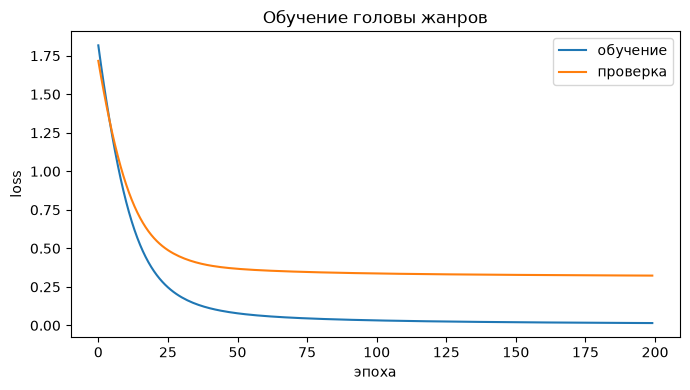

In [6]:
head = nn.Linear(312, len(GENRES))
optimizer = torch.optim.Adam(head.parameters(), lr=0.003, weight_decay=1e-3)
SCALE = 10
history = {"train": [], "test": []}
for epoch in range(200):
    loss = F.cross_entropy(head(SCALE * X_train), y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        history["train"].append(loss.item())
        history["test"].append(F.cross_entropy(head(SCALE * X_test), y_test).item())
    if epoch % 40 == 0 or epoch == 199:
        print(f"эпоха {epoch:3d}: loss на обучении {history['train'][-1]:.3f}, на проверке {history['test'][-1]:.3f}")

with torch.no_grad():
    pred2 = head(SCALE * X_test).argmax(1)
print(f"\nСпособ 2, обученная голова: точность {accuracy(pred2, y_test):.0%}")
print(f"весов в голове: {sum(p.numel() for p in head.parameters())} (в BERT под ней — 29 млн, их мы не трогали)")
torch.save({"genres": GENRES, "scale": SCALE, "state": head.state_dict()}, HERE / "genre_head.pt")
print("голова сохранена в genre_head.pt")

plt.figure(figsize=(7, 4))
plt.plot(history["train"], label="обучение")
plt.plot(history["test"], label="проверка")
plt.xlabel("эпоха")
plt.ylabel("loss")
plt.title("Обучение головы жанров")
plt.legend()
plt.tight_layout()
plt.savefig("genre_training.png", dpi=100)
show()

Loss на обучении уходит почти в 0, а на проверке останавливается заметно выше — знакомая по сессии 4 картина:
90 примеров — это очень мало, и голова начинает запоминать именно их. Хорошо, что голова маленькая (1 878 весов) —
переобучиться сильно она не может.

## 5. Что с чем путается: матрица ошибок

Строка — настоящий жанр, столбец — ответ модели. На диагонали — правильные ответы.

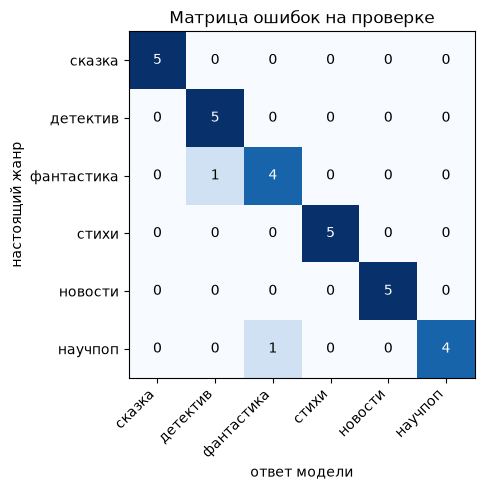

[фантастика → детектив] Киборг-охранник просканировал пропуск и пропустил гостя на станцию. Он не заметил, что у гостя на руке шесть п
[научпоп → фантастика] Мёд почти не портится: археологи находили съедобный мёд в древнеегипетских гробницах. В нём слишком мало воды 


In [7]:
confusion = torch.zeros(len(GENRES), len(GENRES), dtype=torch.int)
for t, p in zip(y_test, pred2):
    confusion[t, p] += 1

plt.figure(figsize=(6, 5))
plt.imshow(confusion, cmap="Blues")
plt.xticks(range(len(GENRES)), GENRES, rotation=45, ha="right")
plt.yticks(range(len(GENRES)), GENRES)
for i in range(len(GENRES)):
    for j in range(len(GENRES)):
        plt.text(j, i, int(confusion[i, j]), ha="center", va="center", color="white" if confusion[i, j] > 2 else "black")
plt.xlabel("ответ модели")
plt.ylabel("настоящий жанр")
plt.title("Матрица ошибок на проверке")
plt.tight_layout()
plt.savefig("genre_confusion.png", dpi=100)
show()

for r, t, p in zip(test, y_test, pred2):
    if t != p:
        print(f"[{GENRES[t]} → {GENRES[p]}] {r['text'][:110]}")

Ошибки «понятные»: киборг-охранник, который чего-то **не заметил**, — это почти детектив, а мёд из древнеегипетских гробниц
с археологами звучит как приключение. Граница между жанрами размыта и для людей — попробуйте сами отнести эти отрывки
к одному жанру и сравните ответы в классе.

## 6. Сколько нужно примеров?

Повторим обучение, давая модели 1, 2, 3, 5, 10 и 15 примеров на жанр. Для каждого числа — 20 раз со случайным выбором примеров,
точность усредним. Так видно, сколько данных на самом деле нужно, когда под головой стоит готовая умная модель.

 1 примеров на жанр: средний вектор 60%, голова 59%


 2 примеров на жанр: средний вектор 73%, голова 72%


 3 примеров на жанр: средний вектор 78%, голова 77%


 5 примеров на жанр: средний вектор 83%, голова 83%


10 примеров на жанр: средний вектор 87%, голова 88%


15 примеров на жанр: средний вектор 90%, голова 93%


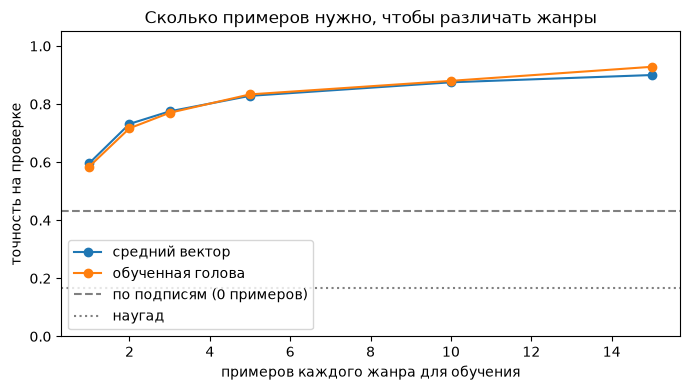

In [8]:
def train_head(X, y, epochs=200):
    h = nn.Linear(X.shape[1], len(GENRES))
    opt = torch.optim.Adam(h.parameters(), lr=0.003, weight_decay=1e-3)
    for _ in range(epochs):
        loss = F.cross_entropy(h(SCALE * X), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return h


shots = [1, 2, 3, 5, 10, 15]
curves = {"средний вектор": [], "обученная голова": []}
for k in shots:
    acc_c, acc_h = [], []
    for trial in range(20):
        idx = torch.cat([torch.nonzero(y_train == g).view(-1)[torch.randperm(15)[:k]] for g in range(len(GENRES))])
        Xk, yk = X_train[idx], y_train[idx]
        c = F.normalize(torch.stack([Xk[yk == g].mean(0) for g in range(len(GENRES))]), dim=-1)
        acc_c.append(accuracy((X_test @ c.T).argmax(1), y_test))
        h = train_head(Xk, yk)
        with torch.no_grad():
            acc_h.append(accuracy(h(SCALE * X_test).argmax(1), y_test))
    curves["средний вектор"].append(sum(acc_c) / len(acc_c))
    curves["обученная голова"].append(sum(acc_h) / len(acc_h))
    print(f"{k:2d} примеров на жанр: средний вектор {curves['средний вектор'][-1]:.0%}, голова {curves['обученная голова'][-1]:.0%}")

plt.figure(figsize=(7, 4))
for name, values in curves.items():
    plt.plot(shots, values, marker="o", label=name)
plt.axhline(accuracy(pred0, y_test), color="gray", linestyle="--", label="по подписям (0 примеров)")
plt.axhline(1 / len(GENRES), color="gray", linestyle=":", label="наугад")
plt.xlabel("примеров каждого жанра для обучения")
plt.ylabel("точность на проверке")
plt.ylim(0, 1.05)
plt.title("Сколько примеров нужно, чтобы различать жанры")
plt.legend()
plt.tight_layout()
plt.savefig("genre_shots.png", dpi=100)
show()

Уже **один пример** на жанр даёт 60% — в 3,5 раза лучше угадывания и лучше подписей, а пять примеров — больше 80%.
Обе кривые почти совпадают: когда векторы хорошие, простое среднее работает почти так же, как обучение. В сессии 3 сети на MNIST нужны были тысячи картинок
на каждую цифру — потому что она училась с нуля. Здесь основную работу сделал BERT, прочитавший миллионы текстов до нас.

## 7. Проверка на «чужих» текстах

Модель видела только наши короткие отрывки. Что она скажет про настоящую литературу и про тексты, которые вы напишете сами?

In [9]:
def predict(text):
    with torch.no_grad():
        probs = torch.softmax(head(SCALE * embed(text)), dim=-1)[0]
    best = probs.argsort(descending=True)[:2].tolist()
    return ", ".join(f"{GENRES[i]} {probs[i]:.0%}" for i in best)


stanza = onegin_stanzas()[0]
others = {
    "«Онегин», первая строфа": stanza,
    "Пушкин, «Сказка о рыбаке и рыбке»": "Жил старик со своею старухой у самого синего моря; они жили в ветхой землянке ровно тридцать лет и три года.",
    "из учебника биологии": "Митохондрии — органоиды клетки, в которых происходит клеточное дыхание и вырабатывается энергия.",
    "спортивная новость": "Футболисты «Зенита» обыграли «Спартак» со счётом 2:1 и вышли на первое место в турнирной таблице.",
    "школьное сочинение": "Летом я ездил к бабушке в деревню. Мы ходили на речку, собирали малину и смотрели на звёзды.",
    "рецепт": "Возьмите три яйца, стакан муки и стакан сахара. Взбейте яйца с сахаром и аккуратно добавьте муку.",
}
for name, text in others.items():
    print(f"{name:35s} → {predict(text)}")

«Онегин», первая строфа             → детектив 62%, стихи 20%
Пушкин, «Сказка о рыбаке и рыбке»   → сказка 89%, фантастика 9%
из учебника биологии                → научпоп 99%, фантастика 1%
спортивная новость                  → новости 92%, фантастика 6%
школьное сочинение                  → сказка 94%, стихи 5%
рецепт                              → сказка 78%, научпоп 17%


**Разбор:**
- биология, спортивная новость и сказка Пушкина — верно, хотя таких текстов в обучении не было;
- школьное сочинение — «сказка»: рассказ в прошедшем времени про бабушку и деревню действительно похож на наши сказки
  больше, чем на остальные пять жанров;
- рецепт — тоже «сказка». Модель **всегда** выбирает один из шести жанров — она не умеет сказать «не знаю»:
  softmax обязан раздать 100% между известными классами. Вспомните сеть из сессии 4, которая уверенно называла кошкой или собакой любую картинку;
- а первая строфа «Онегина» — «детектив»! Почему — разберёмся в следующем пункте.

## 8. Почему «Онегин» — не стихи: BERT не видит строк

Человек узнаёт стихи прежде всего по **форме**: короткие строки, ритм, рифма. Но токенизатор BERT (шаг 1) выбрасывает
переводы строк — для него это просто пробел. Значит, модель видит стихотворение как одну длинную строку и может опираться только на слова.
Наши обучающие стихи — про природу (туман, листья, звёзды), поэтому голова выучила «стихи = слова о природе».
А в первой строфе «Онегина» — болезнь, коварство, лекарство и чёрт: для модели это скорее детектив.

In [10]:
from common import load_tokenizer

bert_tok = load_tokenizer("bert")
print("с переводом строки:", bert_tok("Мой дядя,\nсамых честных")["input_ids"])
print("с пробелом:        ", bert_tok("Мой дядя, самых честных")["input_ids"], "— одно и то же")

stanzas = onegin_stanzas()[:60]
with torch.no_grad():
    answers = head(SCALE * embed(stanzas)).argmax(1)
counts = {g: (answers == i).sum().item() for i, g in enumerate(GENRES)}
print(f"\nПервые {len(stanzas)} строф «Онегина» по мнению модели:", {g: c for g, c in counts.items() if c})

с переводом строки: [2, 33249, 48523, 16, 9532, 81192, 3]
с пробелом:         [2, 33249, 48523, 16, 9532, 81192, 3] — одно и то же

Первые 60 строф «Онегина» по мнению модели: {'сказка': 13, 'детектив': 7, 'фантастика': 2, 'стихи': 38}


Стихами модель называет примерно две трети строф, остальные — сказкой, детективом и даже фантастикой. Чтобы учитывать форму, можно добавить к вектору BERT простые признаки,
которые считаются без нейросети: число строк, среднюю длину строки, долю строк с заглавной буквы. Это хороший пример того,
что готовая модель — не волшебная палочка: важно понимать, **что она видит, а что нет**.

## Попробуйте сами

1. Напишите по одному своему отрывку каждого жанра. Сколько из шести модель угадает?
2. Измените подписи в способе 0 (например, «Жили-были...» вместо «Это сказка»). Получится ли поднять точность?
3. Добавьте седьмой жанр — «рецепт» или «спорт»: 10 отрывков в `genres.csv` (7 — `train`, 3 — `test`). Перезапустите шаг.
4. Уберите `SCALE` (поставьте 1). Как изменятся кривая loss и итоговая точность за 200 эпох?
5. Добавьте в `genres.csv` 5–10 отрывков из «Онегина» как стихи для обучения. Сколько строф теперь узнаются как стихи?
   (Честно проверять нужно на строфах, которых не было в обучении.)
6. *(Сложнее.)* Сделайте признак «число строк в тексте», приклейте его к вектору BERT (`torch.cat`) и обучите голову `Linear(313, 6)`.
   Помогло ли это узнавать стихи?